# Week 11a.1: Context Management

Every agent we've built so far sends its whole message list to the model on every call. Today we'll look at what to do when that list gets too long.

Context grows in two ways.

- **A long conversation.** With a checkpointer, every turn sends the whole history back to the model. Fifty turns in, the model rereads all fifty to answer the fifty-first.
- **A long task.** Every tool result stays in the message list, so an agent that reads twenty documents carries all twenty into every later call.

Either way, each call costs more and takes longer, and eventually the context window runs out. Long before that, models get worse at using information buried in the middle of a long context, as the *Lost in the Middle* paper showed.

To manage the context better, we'll look at three strategies, and try the first two on the support agent:

| Strategy | What the model sees |
|---|---|
| Trimming | only the most recent messages |
| Summarization | a summary of the older messages, plus the recent ones |
| Offloading | old tool results replaced by a pointer to a file |

Each one throws something away. For each, we'll ask what was thrown away, and how we would notice.

In [3]:
from dotenv import load_dotenv
import os

load_dotenv()
keys = ["OPENAI_API_KEY", "ANTHROPIC_API_KEY", "GOOGLE_API_KEY"]
print("API keys found:", [k for k in keys if os.getenv(k)] or "none (fine with Ollama)")

API keys found: ['OPENAI_API_KEY', 'ANTHROPIC_API_KEY', 'GOOGLE_API_KEY']


## 0. Model Setup

Execute one of the following to define the model.

In [ ]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:9b", reasoning=False)

In [4]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="gpt-4.1-mini")

In [ ]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="claude-haiku-5-5")

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

## 1. A long conversation history

We'll use the Husky Tech support agent with the four tools from `support_tools.py` with a checkpointer so the conversation carries over from turn to turn.

`build_support` takes the `assistant` node as an argument, because the strategies in this notebook differ only in what the assistant sends to the model.

In [5]:
from langchain.messages import SystemMessage, HumanMessage, AIMessage, ToolMessage, RemoveMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver

from support_tools import TOOLS, SYSTEM_PROMPT

model_with_tools = model.bind_tools(TOOLS)
sys_msg = SystemMessage(content=SYSTEM_PROMPT)


def build_support(assistant, state=MessagesState):
    builder = StateGraph(state)
    builder.add_node("assistant", assistant)
    builder.add_node("tools", ToolNode(TOOLS))
    builder.add_edge(START, "assistant")
    builder.add_conditional_edges("assistant", tools_condition)
    builder.add_edge("tools", "assistant")
    return builder.compile(checkpointer=InMemorySaver())

Here is the conversation. In the first turn, Dana tells the agent something that matters only in the last turn: she is traveling, and nothing should be delivered before November 20.

In [6]:
TURNS = [
    "Hi, I'm Dana. I'm traveling until November 20, so please don't deliver anything to my address before then.",
    "Where is my order HT-1002?",
    "What about HT-1003?",
    "How long does shipping usually take?",
    "Can I return the headphones from HT-1001?",
    "What is your warranty policy?",
    "What are your support hours?",
    "If you send me a replacement keyboard today, is there anything I told you that affects when it should arrive?",
]


def chat(agent, thread):
    """Run the eight turns on one thread. For each turn, print the input tokens of the model's
    last call and the number of messages in the state."""
    config = {"configurable": {"thread_id": thread}}
    for text in TURNS:
        out = agent.invoke({"messages": [HumanMessage(content=text)]}, config)
        calls = [m for m in out["messages"] if getattr(m, "usage_metadata", None)]
        read = calls[-1].usage_metadata["input_tokens"] if calls else 0
        print(f"{read:6} tokens read {len(out['messages']):4} messages   {text[:55]}")
    print("\nLast reply:", out["messages"][-1].text)
    return agent.get_state(config).values

Full message history:

In [7]:
def assistant(state: MessagesState) -> dict:
    messages = [model_with_tools.invoke([sys_msg] + state["messages"])]
    return {"messages": messages}


agent = build_support(assistant)
results = chat(agent, "full-thread-01")

   297 tokens read    2 messages   Hi, I'm Dana. I'm traveling until November 20, so pleas
   426 tokens read    6 messages   Where is my order HT-1002?
   563 tokens read   10 messages   What about HT-1003?
   666 tokens read   14 messages   How long does shipping usually take?
   836 tokens read   19 messages   Can I return the headphones from HT-1001?
   926 tokens read   23 messages   What is your warranty policy?
  1028 tokens read   27 messages   What are your support hours?
  1094 tokens read   29 messages   If you send me a replacement keyboard today, is there a

Last reply: Yes, you mentioned you are traveling until November 20 and requested that deliveries not be made to your address before then. If we send a replacement keyboard today, delivery should be scheduled for after November 20 to accommodate your travel plans. Would you like me to arrange that for you?


In [8]:
for m in results["messages"]:
    m.pretty_print()


================================ Human Message =================================

Hi, I'm Dana. I'm traveling until November 20, so please don't deliver anything to my address before then.
================================== Ai Message ==================================

Hi Dana, I understand your request to delay delivery until after November 20. Could you please provide me with your order ID(s) so I can check the options for adjusting the delivery date?
================================ Human Message =================================

Where is my order HT-1002?
================================== Ai Message ==================================
Tool Calls:
  look_up_order (call_2VHfjhWxuuiAuYeFqlrrAiu5)
 Call ID: call_2VHfjhWxuuiAuYeFqlrrAiu5
  Args:
    order_id: HT-1002
================================= Tool Message =================================
Name: look_up_order

{'item': 'Mechanical keyboard', 'status': 'shipped', 'ordered_on': '2026-09-15', 'eta': '2026-09-23', 'price': 129.0}
=

Notice that the tokens read go up on every turn, and the number of messages goes up by about four per turn: the question, the tool call, the tool result, and the reply. The last reply should mention Dana's travel dates, because the first message is still in the history.

These numbers are small because the conversation is short. The growth is the same in a conversation of two hundred turns.

## 2. Trimming

The simplest strategy is to send the model only the most recent messages. 
- https://reference.langchain.com/python/langchain-core/messages/utils/trim_messages


`trim_messages` is used for this purpose:
- `strategy="last"` keeps the end of the list
- `max_tokens=600` with `token_counter="approximate"` 
    - keeps about 600 tokens, counted with a rough estimate instead of the model's tokenizer
- `start_on="human"` makes the kept part start at a user message
    - `start_on="human"` matters because of tool calls. If the cut fell between an `AIMessage` with a tool call and the `ToolMessage` that answers it, the model would receive a tool result with no call, and the model APIs reject that history.
- If the current turn alone is longer than `max_tokens`, nothing fits and `trim_messages` returns an empty list.
    - So `MAX_TOKENS` has to be larger than one turn. Claude's replies are much longer than GPT's, so use 1500 with Claude.

**The checkpointer still saves every message. Only the model's view is trimmed.**

In [11]:
from langchain_core.messages import trim_messages

trimmed_results = trim_messages(results["messages"],
                                strategy="last",
                                max_tokens=600,
                                token_counter="approximate",
                                start_on="human")

In [12]:
for m in trimmed_results:
    m.pretty_print()

================================ Human Message =================================

Can I return the headphones from HT-1001?
================================== Ai Message ==================================
Tool Calls:
  look_up_order (call_M7WAG4C6YlBtKlXiepuSZB2C)
 Call ID: call_M7WAG4C6YlBtKlXiepuSZB2C
  Args:
    order_id: HT-1001
  check_return_eligibility (call_aCer1vBUwJOvzwHS7VpoqUi1)
 Call ID: call_aCer1vBUwJOvzwHS7VpoqUi1
  Args:
    order_id: HT-1001
================================= Tool Message =================================
Name: look_up_order

{'item': 'Wireless headphones', 'status': 'delivered', 'delivered_on': '2026-09-05', 'price': 79.99}
================================= Tool Message =================================
Name: check_return_eligibility

Not eligible: delivered 73 days ago, which is past the 30-day window.
================================== Ai Message ==================================

The wireless headphones from your order HT-1001 were delivered 73 da

In [15]:
from langchain_core.messages import trim_messages

MAX_TOKENS = 400   # use 1500 with Claude, whose replies are much longer


def assistant_trimmed(state: MessagesState) -> dict:
    recent = trim_messages(state["messages"], strategy="last", max_tokens=MAX_TOKENS,
                           token_counter="approximate", start_on="human")
    return {"messages": [model_with_tools.invoke([sys_msg] + recent)]}


trimmed = build_support(assistant_trimmed)
trimmed_results = chat(trimmed, "trimmed")

   297 tokens read    2 messages   Hi, I'm Dana. I'm traveling until November 20, so pleas
   421 tokens read    6 messages   Where is my order HT-1002?
   545 tokens read   10 messages   What about HT-1003?
   580 tokens read   14 messages   How long does shipping usually take?
   542 tokens read   18 messages   Can I return the headphones from HT-1001?
   514 tokens read   22 messages   What is your warranty policy?
   511 tokens read   26 messages   What are your support hours?
   475 tokens read   30 messages   If you send me a replacement keyboard today, is there a

Last reply: To assist you accurately with the replacement keyboard shipment and its arrival time, I am escalating your request to a human agent who will follow up within one business day. Thank you for your understanding.


The tokens read climb until they reach the limit, and then they stop growing. The number of messages in the state keeps growing, because nothing was deleted.

Now read the last reply. The travel dates were in the first turn, which fell outside the window several turns ago, so the agent no longer knows about them. Depending on the run, it may also have lost track of which order was the keyboard.

Trimming keeps whatever is recent, which is not always what matters. It is cheap, and it works well when old turns really are irrelevant, such as in a chat where each question stands on its own.

### Trimmed Messages

Because the trimmed list isn't saved anywhere. assistant_trimmed builds it, sends it to the model and discards it. Only the full message list goes into the state.

In [16]:
trimmed_messages = trim_messages(trimmed_results["messages"],
                                strategy="last", 
                                max_tokens=600,token_counter="approximate", start_on="human")

for m in trimmed_messages:
    m.pretty_print()

================================ Human Message =================================

What is your warranty policy?
================================== Ai Message ==================================
Tool Calls:
  search_faq (call_BSDBR9MH3sEXfF7aZYDFJBwv)
 Call ID: call_BSDBR9MH3sEXfF7aZYDFJBwv
  Args:
    question: warranty policy
================================= Tool Message =================================
Name: search_faq

All electronics include a one-year manufacturer warranty.
================================== Ai Message ==================================

All electronics from Husky Tech include a one-year manufacturer warranty. If you have specific questions about a product's warranty, feel free to ask!
================================ Human Message =================================

What are your support hours?
================================== Ai Message ==================================
Tool Calls:
  search_faq (call_DxjnhfnFk81CzNf9V0pQnfjB)
 Call ID: call_DxjnhfnFk81CzNf9V0

In [17]:
trimmed_results["messages"]

[HumanMessage(content="Hi, I'm Dana. I'm traveling until November 20, so please don't deliver anything to my address before then.", additional_kwargs={}, response_metadata={}, id='6f0815c8-85f2-4731-98c1-b796646df4e4'),
 AIMessage(content='Hello Dana, I can assist you with that. Could you please provide me with your order ID(s) so I can check the delivery details and update any necessary instructions?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 297, 'total_tokens': 332, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4.1-mini-2025-04-14', 'system_fingerprint': 'fp_15b2959e0c', 'id': 'chatcmpl-ElFGdx1E98MCXPrdNmcVRBPTtmzv0',

## 3. Summarization

Instead of dropping the old messages, we can replace them with a summary. 

The summary goes in its own key in the state, and the assistant puts it in front of the recent messages when it calls the model.

**Why its own key?** 

If we appended the summary to `messages`, it would land after the recent turns, and the model would read about the start of the conversation last. Keeping it separate lets us put it where it belongs, at the top.

In [20]:
class SupportState(MessagesState):
    summary: str


def assistant_summary(state: SupportState) -> dict:
    history = state["messages"]
    if state.get("summary"):
        history = [SystemMessage(content="Summary of the conversation so far:\n" + state["summary"])] + history
    return {"messages": [model_with_tools.invoke([sys_msg] + history)]}

### The summarize node

The `summarize` node runs at the start of every turn, before the assistant. It does two things.

1. **Decides whether to summarize at all.** Summarizing is an extra model call, so it waits until the state has more than `TRIGGER` messages.
2. **Summarizes and deletes.** It asks the model to fold every message except the customer's new question into the existing summary, and returns a `RemoveMessage` for each of them. The previous turn is complete when this node runs, so a tool call is never separated from its result. `RemoveMessage(id=...)` tells the `add_messages` reducer to delete the message with that id.

The summary prompt says what to keep. Whatever it does not ask for may be lost for good, so it names the things a support conversation cannot afford to lose: facts about the customer, order ids, decisions, and constraints.

In [18]:
TRIGGER = 10   # summarize once the state has more than this many messages

SUMMARY_PROMPT = """Update the summary of a customer support conversation.
Keep every fact the customer gave about themselves, every order id and what was found about it, every
promise or decision, and any constraint the customer asked us to respect. Write short bullet points.

Summary so far:
{summary}

New messages:
{messages}"""



In [21]:
def summarize(state: SupportState) -> dict:
    messages = state["messages"]

    if len(messages) <= TRIGGER:
        return {}
    
    old = "\n".join(f"{m.type}: {m.text}" for m in messages[:-1])   # everything before the new question
    summary_prompt = SUMMARY_PROMPT.format(summary=state.get("summary", ""), messages=old)
    
    summary = model.invoke(summary_prompt).text

    updated_messages = [RemoveMessage(id=m.id) for m in messages[:-1]]

    return {"summary": summary, "messages": updated_messages}

The graph is the support loop with one change: every turn starts at `summarize` instead of `assistant`.

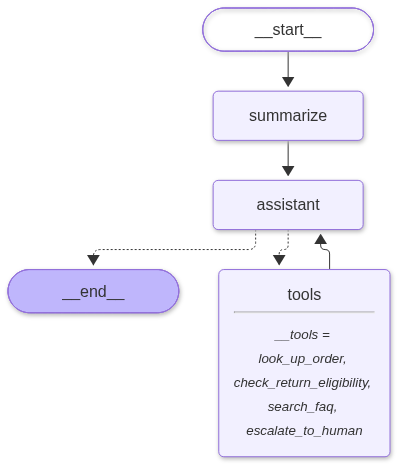

In [22]:
from IPython.display import Image, display

builder = StateGraph(SupportState)
builder.add_node("assistant", assistant_summary)
builder.add_node("tools", ToolNode(TOOLS))
builder.add_node("summarize", summarize)
builder.add_edge(START, "summarize")
builder.add_edge("summarize", "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")
summarized = builder.compile(checkpointer=InMemorySaver())

display(Image(summarized.get_graph().draw_mermaid_png()))

In [23]:
summarized_results = chat(summarized, "summarized")

   297 tokens read    2 messages   Hi, I'm Dana. I'm traveling until November 20, so pleas
   435 tokens read    6 messages   Where is my order HT-1002?
   555 tokens read   10 messages   What about HT-1003?
   441 tokens read    4 messages   How long does shipping usually take?
   613 tokens read    9 messages   Can I return the headphones from HT-1001?
   721 tokens read   13 messages   What is your warranty policy?
   515 tokens read    4 messages   What are your support hours?
   645 tokens read    8 messages   If you send me a replacement keyboard today, is there a

Last reply: You mentioned you are traveling until November 20 and requested no deliveries to your address before then. If we send a replacement keyboard today, it would typically arrive in 3-5 business days with standard shipping, but we should hold the delivery until after November 20 to respect your request. 
Would you like me to note that for a replacement shipment?


This time the number of messages stays small, because old messages are deleted from the state, and the tokens read level off. The last reply should mention the travel dates again. They are not in any message anymore, but they are in the summary.

In [24]:
print(summarized_results["summary"])

- Customer name: Dana  
- Dana is traveling until November 20 and requests no deliveries to her address before then  
- Order HT-1001: Wireless headphones, delivered on 2026-09-05, price $79.99  
  - Not eligible for return (delivered 73 days ago, past 30-day return window)  
- Order HT-1002: Mechanical keyboard, shipped on 2026-09-15, ETA 2026-09-23, price $129.00  
- Order HT-1003: USB-C dock, ordered on 2026-09-18, currently processing, price $59.50  
- Standard shipping takes 3-5 business days, orders over $50 ship free  
- All electronics include a one-year manufacturer warranty  
- Advised Dana to contact support closer to November 20 for delivery rescheduling or holds


In [25]:
print("summarized:", len(summarized_results["messages"]), "messages")

summarized: 8 messages


In [26]:
for m in summarized_results["messages"]:
    m.pretty_print()

================================ Human Message =================================

What are your support hours?
================================== Ai Message ==================================
Tool Calls:
  search_faq (call_r7NSxzcTkkv2Gk7a5sT313Wr)
 Call ID: call_r7NSxzcTkkv2Gk7a5sT313Wr
  Args:
    question: support hours
================================= Tool Message =================================
Name: search_faq

Support is available Monday through Friday, 9am to 6pm ET.
================================== Ai Message ==================================

Our support hours are Monday through Friday, 9am to 6pm ET. Let me know if you need any other help!
================================ Human Message =================================

If you send me a replacement keyboard today, is there anything I told you that affects when it should arrive?
================================== Ai Message ==================================
Tool Calls:
  look_up_order (call_BGHe1W20Q4lMasyo3GsFrI28)
 C

Read the summary and check it against the conversation. A summary is lossy by design.

- It keeps what the prompt asked for. Change the prompt to "Summarize this conversation." and run it again, and constraints like the travel dates are often among the first things to go.
- It can be wrong. The model writes the summary, and a mistake in it is carried forward on every later turn, because the original messages are gone.
- It costs a model call every time it runs, which is why we wait for `TRIGGER`.

NOTE:

`langchain` ships this strategy as `SummarizationMiddleware`, with the trigger and the number of messages to keep as arguments:

```python
agent = create_agent(model, 
                    tools=TOOLS, 
                    system_prompt=SYSTEM_PROMPT, 
                    checkpointer=InMemorySaver(),
                    middleware=[SummarizationMiddleware(
                                model, 
                                trigger=("tokens", 600), 
                                keep=("messages", 4))]
                    )

```

The deep agents from Week 9 use it by default, so a deep agent's lead summarizes its own history when it gets long.

### Summarizing at a token count

`TRIGGER` counts messages. Claude Code and `SummarizationMiddleware` count tokens instead, because the context window is measured in tokens, and one long tool result can take up more of it than ten short messages.

Only the check at the top of the node changes. `count_tokens_approximately` estimates the tokens in a list of messages, with the same rough count that `trim_messages` used in section 2.

In [27]:
from langchain_core.messages.utils import count_tokens_approximately

TRIGGER_TOKENS = 600   # summarize once the messages pass this many tokens


def summarize_by_tokens(state: SupportState) -> dict:
    messages = state["messages"]

    if count_tokens_approximately(messages) <= TRIGGER_TOKENS:
        return {}

    old = "\n".join(f"{m.type}: {m.text}" for m in messages[:-1])   # everything before the new question
    summary_prompt = SUMMARY_PROMPT.format(summary=state.get("summary", ""), messages=old)

    summary = model.invoke(summary_prompt).text

    updated_messages = [RemoveMessage(id=m.id) for m in messages[:-1]]

    return {"summary": summary, "messages": updated_messages}

The graph is the same, with `summarize_by_tokens` as the `summarize` node.

In [28]:
builder = StateGraph(SupportState)
builder.add_node("assistant", assistant_summary)
builder.add_node("tools", ToolNode(TOOLS))
builder.add_node("summarize", summarize_by_tokens)
builder.add_edge(START, "summarize")
builder.add_edge("summarize", "assistant")
builder.add_conditional_edges("assistant", tools_condition)
builder.add_edge("tools", "assistant")
summarized_tokens = builder.compile(checkpointer=InMemorySaver())

tokens_results = chat(summarized_tokens, "summarized-tokens")

   297 tokens read    2 messages   Hi, I'm Dana. I'm traveling until November 20, so pleas
   422 tokens read    6 messages   Where is my order HT-1002?
   549 tokens read   10 messages   What about HT-1003?
   650 tokens read   14 messages   How long does shipping usually take?
   828 tokens read   19 messages   Can I return the headphones from HT-1001?
   516 tokens read    4 messages   What is your warranty policy?
   600 tokens read    8 messages   What are your support hours?
   660 tokens read   10 messages   If you send me a replacement keyboard today, is there a

Last reply: Yes, you mentioned you are traveling until November 20 and requested no deliveries before then. We can hold the replacement keyboard delivery until after November 20 to accommodate your schedule. Would you like us to do that?


Compare the messages column with the run above. This version waits until the messages pass 600 tokens, so it summarizes less often, and the size of each turn decides when, not the number of messages.

With Claude, each reply also carries an encrypted record of the model's reasoning, which the estimate counts as text, so it summarizes sooner.

## 4. Long tasks: offloading tool results

Trimming and summarization handle a long conversation. In a long task, such as the research agent from Week 7 reading a dozen abstracts, most of the context is tool results instead.

The model needs a tool result once, right after the tool runs, to decide what to do next. After that, it may never need the full text again. Offloading keeps the full result in a file and shows the model a pointer to it:

- the full result is saved to a file, such as `/results/<tool call id>.txt`
- the message the model sees holds only the path, sometimes with a short preview
- a `read_file` tool lets the model read the full result again when it needs it

Nothing is lost, since every result can be read back, but the agent has to know that it needs something before it can get it.

Deep agents do this automatically: a tool result longer than 20,000 tokens is written to a file right away, and the message keeps a preview and the path.

## 5. Choosing a strategy

| | Trimming | Summarization | Offloading |
|---|---|---|---|
| what the model sees | the recent messages | a summary and the recent messages | pointers to old tool results, and everything else |
| what is lost | everything outside the window | whatever the summary leaves out | nothing, if the agent reads the files back |
| extra cost | none | a model call each time it summarizes | a `read_file` call when the agent needs a result again |
| how you would notice a loss | the agent asks for something it was told, or contradicts it | the summary is missing a fact, or states it wrongly | the report cites fewer sources, or the agent repeats a search |
| suits | chats where each question stands on its own | long conversations | long tasks with large tool results |

In practice, the strategies are combined. The deep agents from Week 9 offload large tool results and summarize their history when it gets long. They also add a fourth strategy: a long subtask goes to a subagent that has its own context, so the subtask's tool results never enter the lead's messages.

## 6. Things to try

1. In the summarization section, change `SUMMARY_PROMPT` to "Summarize this conversation.\n\n{summary}\n{messages}" and run the eight turns again on a new thread. Is the travel constraint still in the summary? Does the last reply still mention it?

2. Set `TRIGGER = 4`. How many model calls does the conversation take now, counting the summaries? Does the agent still know which order was the keyboard?

3. In `assistant_trimmed`, raise `max_tokens` until the last reply mentions the travel dates again. How many tokens did that take, and what does that tell you about trimming in a conversation of two hundred turns?

In [ ]:
# your experiments here